# F7: P7 on E7 — how many investors must know the graph?

**Question P7:** what share of the investors must know the dependencies between companies for the wave to pass, and
do they cause overshoot?

**Experiment E7** (`configs/f7_e7_network{0,25,50}.yaml`): the market of E5 (`real_v1`, real 2024–2025 signals,
502 sessions, herding h = 0.2) with 500 investors: 300 valuers, 100 trend followers, 100 noise traders. Only the
split of the valuers changes: **0, 125 or 250 network valuers** (0%, 25%, 50% of the investors), the rest myopic;
30 seeds each (3001–3030, the seeds of E5) = 90 runs. The mixed cell of E5 at h = 0.2 has the same parameters with
150 network valuers (30%) and is shown as a fourth point.

**What the two kinds of valuers know.** A network valuer uses the full weights of `real_v1`, including company
parents (VLO ← COP, EOG), and reads the parents' prices on the exchange. A myopic valuer uses the *direct* weights:
a regression of the company on its external parents only. On the real graph these direct weights already contain
most of the indirect path: for VLO the direct weights are oil 0.43 and S&P 500 0.60, while the full graph implies
0.42 and 0.61 through COP and EOG. So, unlike the synthetic chain of F5 (where the myopic valuers of the second link
had no oil weight and the wave stopped), the myopic valuers here can carry the wave by themselves.

**Metrics and statistics:** as in `07_e5_propagation.ipynb` (one value per run after warmup; paired contrasts on the
same seeds with a 95% bootstrap over seeds; collapsed runs dropped and counted). Added for P7:

- `pass2_d1`, `pass2_d2`, `pass2_d3`: `day0 + day1` for the links 1, 2, 3 from oil — the share of a move of R that
  reaches the price within two days (1 = the whole wave passes);
- `pass2_tech`, `corr_tech`: the same and the correlation with R for GOOGL and META, whose only company parents
  are NVDA and AMD (edges that only network valuers know);
- `corr_d2`: correlation with R of the refiners.


In [1]:
import math
import multiprocessing as mp
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from marketsim.metrics import as_of, price_series, reference_series, wave_metrics
from marketsim.sim.log_schema import load_run

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
E7, E5 = ROOT / "runs" / "f7" / "e7", ROOT / "runs" / "f6" / "v1" / "e5"
WARMUP = 10
GROUPS = {"d1": ["COP", "EOG"], "d2": ["VLO", "MPC"], "d3": ["DAL", "UAL", "ODFL"], "tech": ["GOOGL", "META"]}
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)

sources = []
for share in (0, 25, 50):
    s = pd.read_csv(E7 / f"network{share}" / "summary.csv")[["run_id", "seed"]]
    sources.append(s.assign(share=share, directory=str(E7 / f"network{share}")))
e5 = pd.read_csv(E5 / "summary.csv")
e5 = e5.loc[(e5["agents.composition"] == "mixed") & (e5["agents.herding.h"] == 0.2), ["run_id", "seed"]]
sources.append(e5.assign(share=30, directory=str(E5)))
sources = pd.concat(sources, ignore_index=True)
print(sources.groupby("share").size().to_dict())


{0: 30, 25: 30, 30: 30, 50: 30}


In [2]:
def ols_day0_day1(r, q):
    y, x0, x1 = r[1:].ravel(), q[1:].ravel(), q[:-1].ravel()
    ok = np.isfinite(y) & np.isfinite(x0) & np.isfinite(x1)
    beta = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), x0[ok], x1[ok]]), y[ok], rcond=None)[0]
    return beta[1], beta[2]


def run_metrics(path):
    log = load_run(path)
    tickers = log.meta["assets"]
    n = log.meta["config"]["n_sessions"]
    ends = np.arange(n) + 1 - 1e-9
    P = np.column_stack([as_of(price_series(log, a), ends) for a in range(len(tickers))])
    R = np.column_stack([as_of(reference_series(log, a), ends) for a in range(len(tickers))])
    P, R = pd.DataFrame(P, columns=tickers).ffill(), pd.DataFrame(R, columns=tickers)
    gap = np.log(P / R).iloc[WARMUP:]
    r, q = np.log(P).diff().iloc[WARMUP + 1:], np.log(R).diff().iloc[WARMUP + 1:]
    out = {"run_id": Path(path).name}
    out["day0"], out["day1"] = ols_day0_day1(r.to_numpy(), q.to_numpy())
    corr = r.corrwith(q)
    for name, members in GROUPS.items():
        b0, b1 = ols_day0_day1(r[members].to_numpy(), q[members].to_numpy())
        out[f"day1_{name}"], out[f"pass2_{name}"] = b1, b0 + b1
        out[f"corr_{name}"] = float(corr[members].mean())
    wave = [wave_metrics(log, a, t0=float(WARMUP), step=0.25, max_lag=12) for a in range(len(tickers))]
    out["lag"] = float(np.nanmean([w["lag_sessions"] for w in wave]))
    out["vol_amp"] = float(np.nanmedian([w["volatility_amplification"] for w in wave]))
    out["corr_R"] = float(corr.median())
    out["gap_days"] = int((gap.abs() > 0.10).to_numpy().sum())
    out["acf1"] = float(np.mean([r[t].autocorr(1) for t in tickers]))
    out["worst_gap"] = float(gap.abs().to_numpy().max())
    out["collapse"] = bool(out["worst_gap"] > math.log(2))
    return out


cache = E7 / "p7_metrics.csv"
known = pd.read_csv(cache) if cache.exists() else pd.DataFrame(columns=["run_id"])
todo = sources.loc[~sources.run_id.isin(set(known.run_id))]
if len(todo):
    with mp.get_context("fork").Pool(8) as pool:
        new = pool.map(run_metrics, [str(Path(d) / r) for d, r in zip(todo.directory, todo.run_id)])
    known = pd.concat([known, pd.DataFrame(new)], ignore_index=True)
    known.to_csv(cache, index=False)
runs = sources.merge(known, on="run_id")
runs["collapse"] = runs["collapse"].astype(bool)
METRICS = ["day0", "day1", "pass2_d1", "pass2_d2", "pass2_d3", "day1_d2", "corr_d2", "pass2_tech", "corr_tech",
           "lag", "vol_amp", "corr_R", "gap_days", "acf1"]
print(len(runs), "runs; collapsed:", runs.groupby("share").collapse.sum().to_dict())


120 runs; collapsed: {0: 0, 25: 0, 30: 0, 50: 0}


## 1. The cells

Means over the runs without collapses; 30% is the mixed cell of E5 at h = 0.2. Second table: standard errors.


In [3]:
ok = runs.loc[~runs.collapse]
display(ok.groupby("share")[METRICS].mean().round(3))
ok.groupby("share")[METRICS].sem().round(3)


,day0,day1,pass2_d1,pass2_d2,pass2_d3,day1_d2,corr_d2,pass2_tech,corr_tech,lag,vol_amp,corr_R,gap_days,acf1
share,,,,,,,,,,,,,,
0,1.051,0.158,1.192,1.187,1.215,-0.090,0.828,1.239,0.785,0.613,1.391,0.817,15.767,-0.068
25,1.040,0.177,1.189,1.295,1.241,0.182,0.752,1.241,0.782,0.630,1.388,0.804,21.200,-0.052
30,1.040,0.184,1.185,1.331,1.257,0.243,0.735,1.243,0.774,0.649,1.395,0.802,17.200,-0.050
50,1.027,0.206,1.188,1.455,1.267,0.440,0.632,1.250,0.773,0.665,1.411,0.782,21.000,-0.046


,day0,day1,pass2_d1,pass2_d2,pass2_d3,day1_d2,corr_d2,pass2_tech,corr_tech,lag,vol_amp,corr_R,gap_days,acf1
share,,,,,,,,,,,,,,
0,0.004,0.005,0.011,0.014,0.009,0.017,0.006,0.009,0.010,0.004,0.005,0.003,2.468,0.003
25,0.004,0.005,0.014,0.014,0.010,0.020,0.010,0.010,0.012,0.007,0.005,0.003,3.827,0.003
30,0.004,0.004,0.012,0.013,0.013,0.020,0.010,0.010,0.011,0.006,0.004,0.004,3.119,0.003
50,0.004,0.005,0.014,0.017,0.008,0.024,0.010,0.009,0.010,0.006,0.007,0.004,4.741,0.003


## 2. Paired contrasts (same seeds)

`clear`: the 95% interval excludes 0; `clear (Bonferroni)`: the interval at 1 − 0.05/3 (three contrasts per metric)
excludes 0.


In [4]:
LEVEL = 1 - 0.05 / 3


def paired(a, b, metric, rng, draws=5000):
    x = a.set_index("seed")[[metric, "collapse"]].join(b.set_index("seed")[[metric, "collapse"]],
                                                      lsuffix="_a", rsuffix="_b", how="inner")
    x = x.loc[~x.collapse_a & ~x.collapse_b]
    d = (x[metric + "_a"] - x[metric + "_b"]).to_numpy(dtype=float)
    boot = rng.choice(d, (draws, len(d))).mean(axis=1)
    lo, hi = np.quantile(boot, [0.025, 0.975])
    blo, bhi = np.quantile(boot, [(1 - LEVEL) / 2, 1 - (1 - LEVEL) / 2])
    return {"pairs": len(d), "mean": d.mean(), "ci_low": lo, "ci_high": hi, "clear": lo > 0 or hi < 0,
            "clear (Bonferroni)": blo > 0 or bhi < 0}


rng = np.random.default_rng(2027)
cell = {share: g for share, g in runs.groupby("share")}
C = pd.DataFrame([{"metric": m, "contrast": f"{a}% − {b}%", **paired(cell[a], cell[b], m, rng)}
                  for m in METRICS for a, b in ((25, 0), (50, 0), (50, 25))])
C.to_csv(E7 / "p7_contrasts.csv", index=False)
C.round(4)


,metric,contrast,pairs,mean,ci_low,ci_high,clear,clear (Bonferroni)
0,day0,25% − 0%,30,-0.0108,-0.0175,-0.0040,True,True
1,day0,50% − 0%,30,-0.0238,-0.0332,-0.0144,True,True
2,day0,50% − 25%,30,-0.0130,-0.0204,-0.0055,True,True
3,day1,25% − 0%,30,0.0197,0.0104,0.0292,True,True
4,day1,50% − 0%,30,0.0487,0.0387,0.0590,True,True
5,day1,50% − 25%,30,0.0290,0.0203,0.0373,True,True
6,pass2_d1,25% − 0%,30,-0.0029,-0.0267,0.0209,False,False
7,pass2_d1,50% − 0%,30,-0.0034,-0.0250,0.0172,False,False
8,pass2_d1,50% − 25%,30,-0.0005,-0.0224,0.0224,False,False
9,pass2_d2,25% − 0%,30,0.1074,0.0814,0.1339,True,True


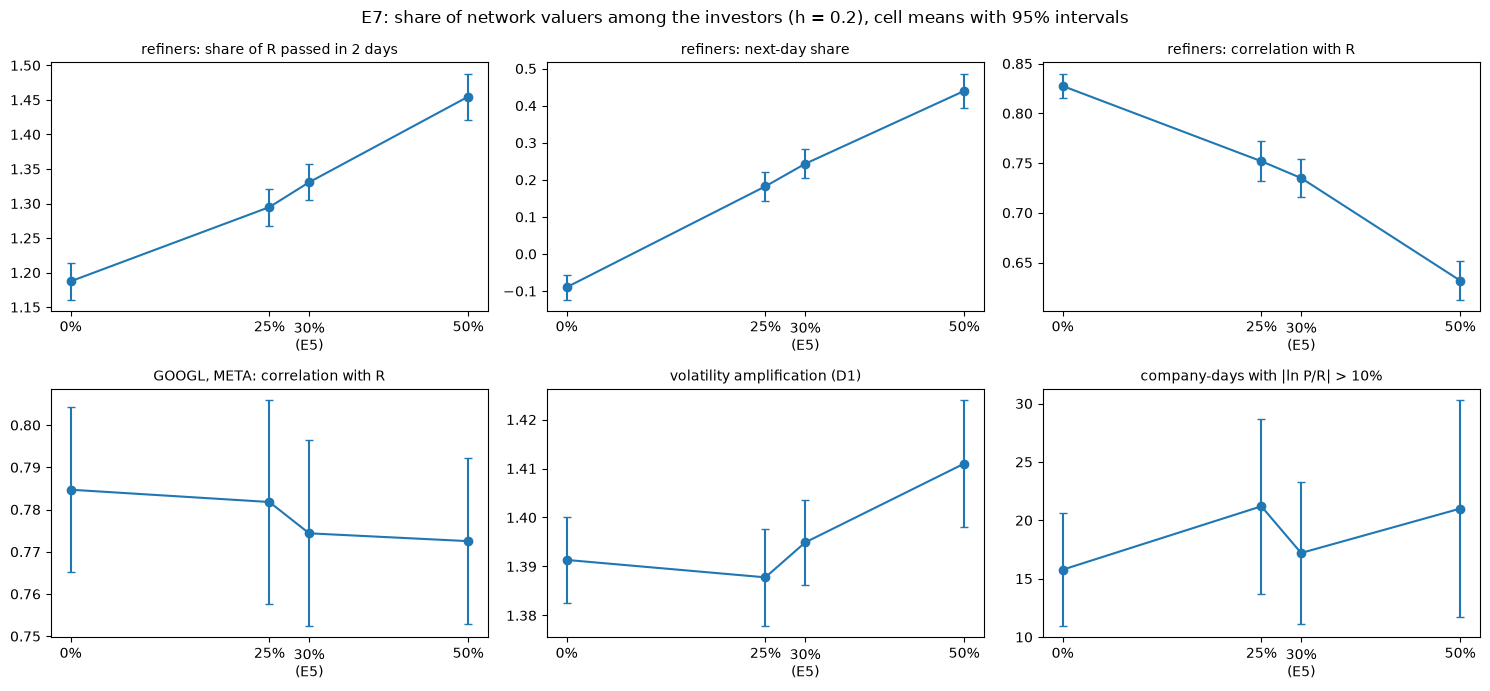

In [5]:
shown = [("pass2_d2", "refiners: share of R passed in 2 days"), ("day1_d2", "refiners: next-day share"),
         ("corr_d2", "refiners: correlation with R"), ("corr_tech", "GOOGL, META: correlation with R"),
         ("vol_amp", "volatility amplification (D1)"), ("gap_days", "company-days with |ln P/R| > 10%")]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (metric, title) in zip(axes.flat, shown):
    g = ok.groupby("share")[metric]
    m, se = g.mean(), g.sem()
    ax.errorbar(m.index, m, yerr=1.96 * se, fmt="o-", capsize=3)
    ax.set_xticks([0, 25, 30, 50], ["0%", "25%", "30%\n(E5)", "50%"])
    ax.set_title(title, fontsize=10)
fig.suptitle("E7: share of network valuers among the investors (h = 0.2), cell means with 95% intervals")
plt.tight_layout()
plt.show()


## 3. What E7 says about P7

All 120 runs (90 of E7 and the 30 of the E5 mixed cell) finish without a collapse. Contrasts: paired on the same
seeds, 95% bootstrap intervals; all differences quoted as clear survive the Bonferroni level.

- **No share of network valuers is needed for the wave to pass.** With 0% network valuers the refiners (two links
  from oil) pass 1.19 of a move of R within two days, exactly as much as the producers (one link, 1.19), and their
  daily returns correlate with R at 0.83, the best of all cells. The myopic valuers carry the wave by themselves
  because their direct weights already contain the path through COP and EOG.
- **Network valuers bring delay and overshoot on the link they know.** For the refiners, from 0% to 25% to 50%
  network valuers:
  - the next-day share grows from −0.09 to +0.18 to +0.44 (+0.27 [0.23; 0.32] and +0.53 [0.48; 0.58]);
  - the share passed within two days grows from 1.19 to 1.30 to 1.46 (+0.11 [0.08; 0.13] and +0.27 [0.24; 0.30]):
    the second link overshoots more;
  - the correlation with R falls from 0.83 to 0.75 to 0.63 (−0.08 and −0.20).

  The E5 mixed cell (30%) lies on the same line (next-day share 0.24, two-day share 1.33, correlation 0.74).
- **The rest of the market hardly changes.** The producers do not differ at all; the airlines and trucking pass a
  little more (+0.03 and +0.05 at 25% and 50%); GOOGL and META, whose company parents NVDA and AMD have weights
  below 0.1, do not differ. Market-wide at 50% against 0%: the D1 lag is longer by 0.05 session, volatility
  amplification larger by 0.02, correlation with R lower by 0.035; company-days off R do not change clearly.

**Short answer to P7.** On the real graph the wave passes with no network valuers at all; each additional network
valuer makes the refiners — the only link where the graph has strong company edges — slower and more overshooting,
roughly in proportion to their share. This differs from the synthetic chain of F5, where myopic valuers of the
second link knew no oil weight and the wave stopped without network valuers: whether "knowing the graph" is needed
depends on whether the simple model already contains the indirect exposure.

**What E7 cannot show.** The simulation has no company news: R is driven by the five external series only. A
network valuer can only gain over a myopic one when a parent company moves for its own reasons (news about COP).
E7 therefore measures only the cost of knowing the graph (reading noisy exchange prices of the parents); the benefit
is a question for E6, which shocks a single company.
